In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("data/housing.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
df.shape

(545, 13)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [7]:
# check for missing values
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [8]:
#. check duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
# Display unique values in categorical columns
for column in df.select_dtypes(include=['object']).columns:
    unique_values = df[column].unique()
    print(f"Unique values in '{column}': {unique_values}")


Unique values in 'mainroad': ['yes' 'no']
Unique values in 'guestroom': ['no' 'yes']
Unique values in 'basement': ['no' 'yes']
Unique values in 'hotwaterheating': ['no' 'yes']
Unique values in 'airconditioning': ['yes' 'no']
Unique values in 'prefarea': ['yes' 'no']
Unique values in 'furnishingstatus': ['furnished' 'semi-furnished' 'unfurnished']


In [10]:
# Separate numerical and categorical columns.
numerical_columns = df.select_dtypes(include=[np.number]).columns
categorical_columns = df.select_dtypes(include=['object']).columns


In [15]:
# Outlier detection
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of price outliers:", len(outliers))

display(outliers[["price", "area", "bedrooms"]])

Lower limit: -35000.0
Upper limit: 9205000.0
Number of price outliers: 15


,price,area,bedrooms
0,13300000,7420,4
1,12250000,8960,4
2,12250000,9960,3
3,12215000,7500,4
4,11410000,7420,4
5,10850000,7500,3
6,10150000,8580,4
7,10150000,16200,5
8,9870000,8100,4
9,9800000,5750,3


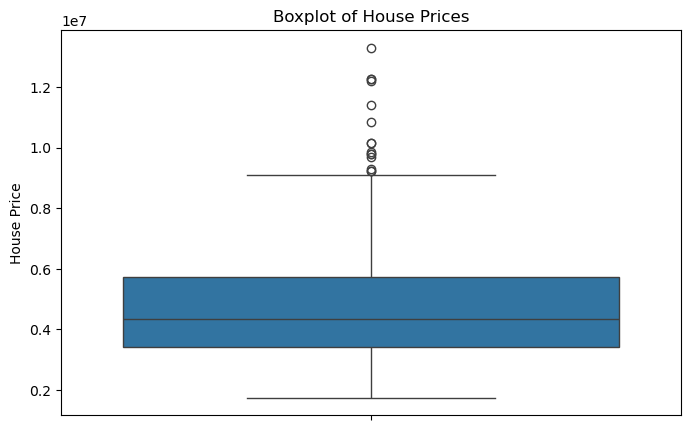

In [11]:
# Outlier detection
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="price")

plt.title("Boxplot of House Prices")
plt.ylabel("House Price")

plt.show()

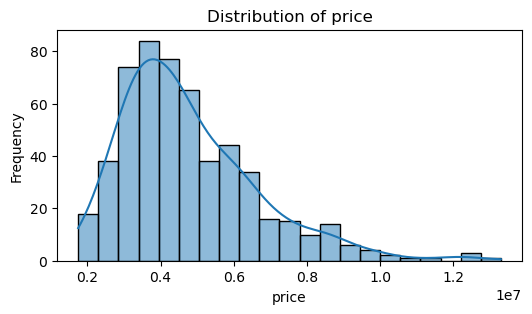

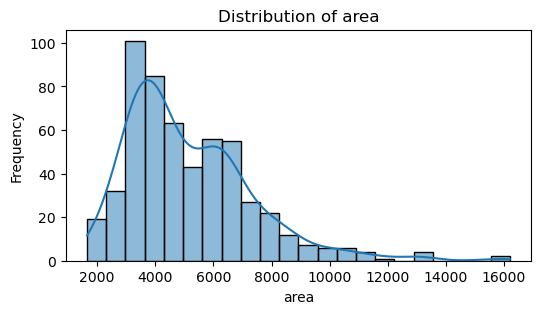

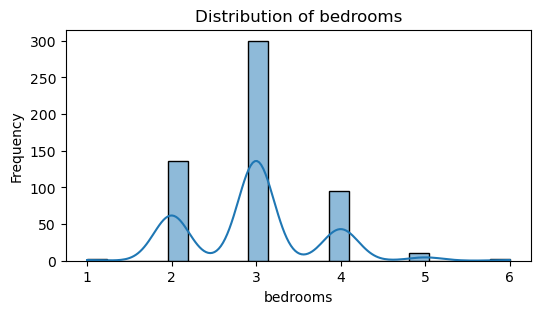

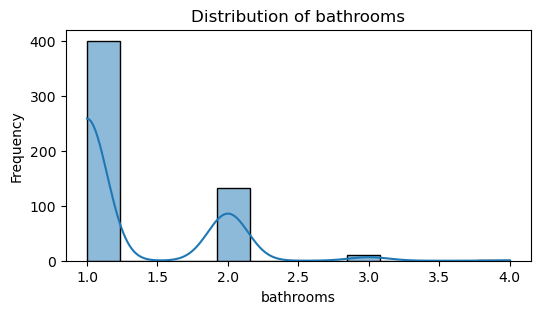

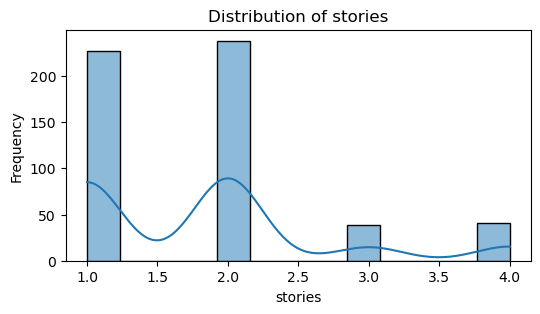

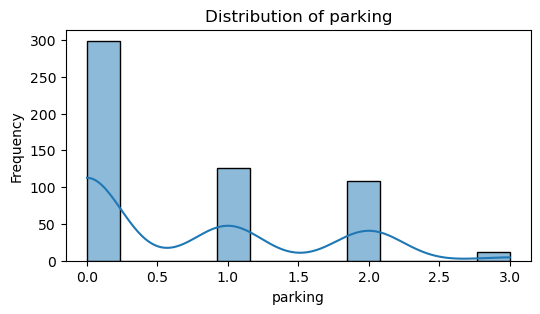

In [12]:
# Explore numerical distributions.
for column in numerical_columns:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[column], kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

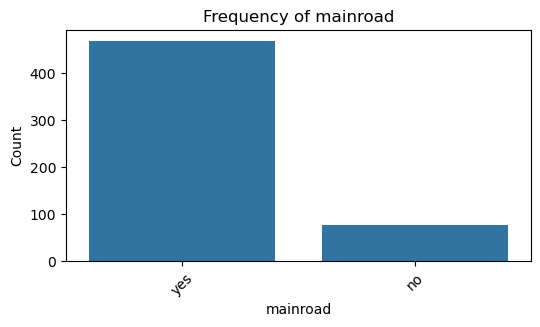

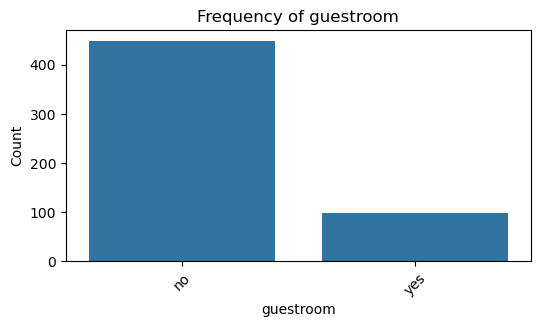

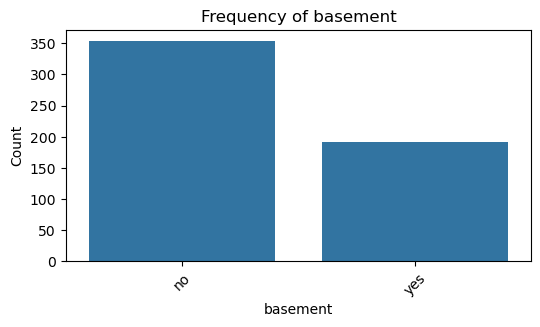

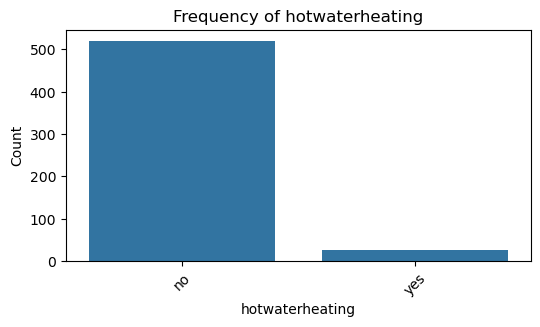

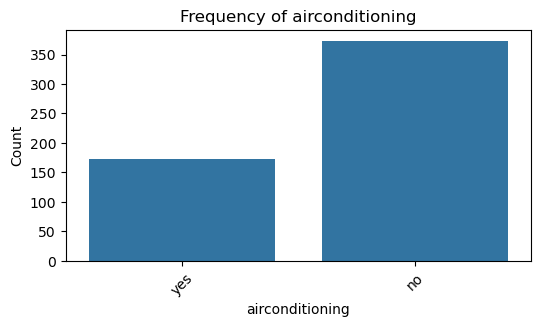

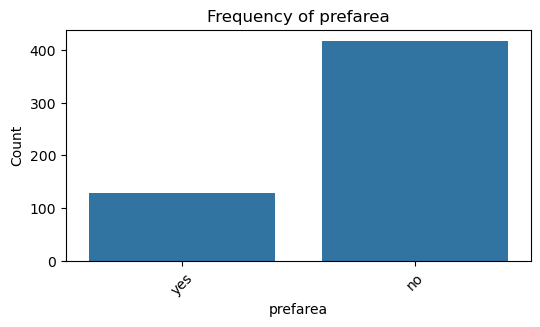

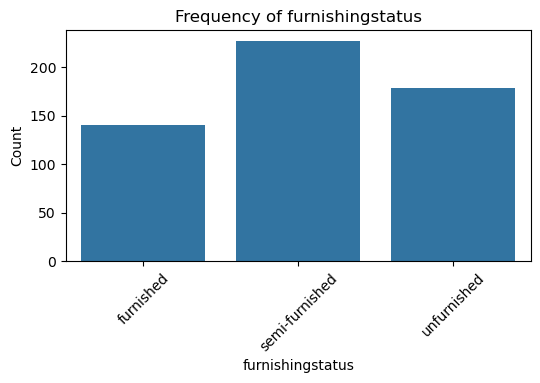

In [13]:
# Analyse categorical frequencies.
for column in categorical_columns:
    plt.figure(figsize=(6, 3))
    sns.countplot(data=df, x=column)
    plt.title(f'Frequency of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

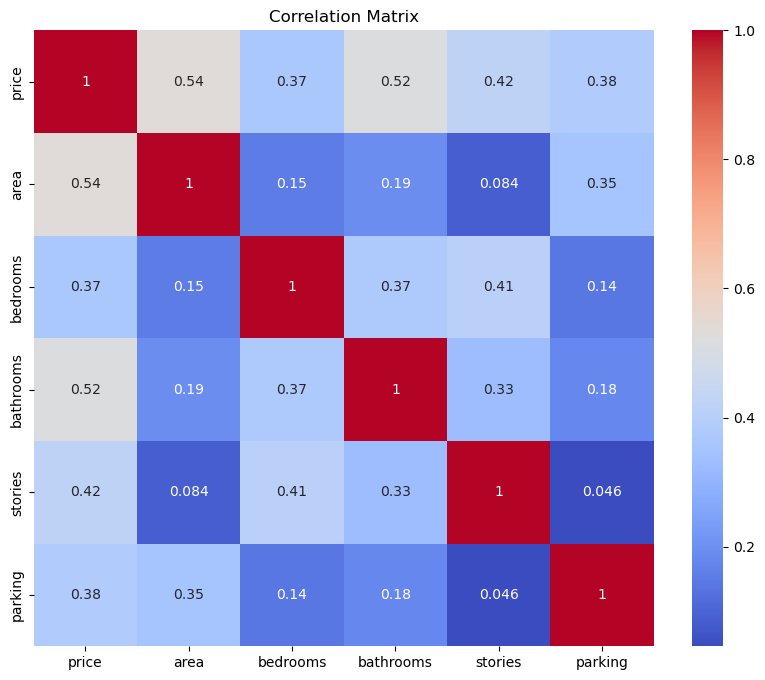

In [14]:
# correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_columns].corr(), annot=True, cmap='coolwarm')  
plt.title('Correlation Matrix')
plt.show()

##### Mean: The mean is the average of all values.
##### Median: The median is the middle value when data is arranged in order. 
##### Variance: Variance measures how far the data values are spread out from the mean. 
##### Standard deviation: Standard deviation shows how much the values typically differ from the mean.
##### Correlation: Correlation measures the strength and direction of the relationship between two numerical variables.

### Key Findings from Exploratory Data Analysis
- The dataset contains 545 housing records and 13 columns. There are no missing values or duplicate records, so the dataset is relatively clean.

- The average house price is approximately 4.77 million, while the median price is 4.34 million. This indicates that some expensive houses increase the overall average price.

- House area has a positive correlation of approximately 0.54 with house price. This suggests that larger houses generally tend to have higher prices.

- Bathrooms also have a positive correlation of approximately 0.52 with house price. Houses with more bathrooms tend to be more expensive.

- The outlier analysis identified 15 potential outliers in house prices and 12 in house areas. These values should be investigated because they may represent unusually expensive or large properties.

- Semi-furnished houses are the most common category, with 227 records. Furnished houses are the least common, with 140 records.

- Most houses have main-road access (468 records), while 77 houses do not have main-road access.

- The dataset does not contain a specific classification target. Therefore, traditional target-class balance analysis is not applicable, although categorical feature distributions can still be examined.